# Настройка архитектуры нейронной сети

**Задача:** регрессия на датасете elevators (OpenML task 361074, бенчмарк Grinsztajn et al., 2022): по 16 признакам состояния самолета F16 предсказать управляющее воздействие на рули высоты.

**Метрика:** nRMSE = RMSE / std(y). Это RMSE в единицах стандартного отклонения таргета: константный прогноз дает примерно 1 - чем меньше, тем лучше. Метрика взята из статьи *Holzmüller, Grinsztajn, Steinwart. Better by Default: Strong Pre-Tuned MLPs and Boosted Trees on Tabular Data (NeurIPS 2024)*, поэтому результаты можно сравнить с ее таблицами D.11–D.12.

**План**

| Шаг задания | Раздел ноутбука |
|---|---|
| 1–3. Данные, метрика, сплит train/val/test | §1 |
| 4. Поиск архитектуры через Optuna | §3 |
| 6. Итерации с LLM | §4 |
| 7. Сравнение на тесте: качество ± 95% ДИ, время, параметры, кривые обучения | §5 |

In [1]:
import os
from pathlib import Path

# Пути относительно папки automl (в Colab: Path('/content/drive/MyDrive/elevators_lab'))
ROOT = Path(os.environ.get('LAB_ROOT', '.'))

DATA_DIR, RESULTS_DIR = ROOT / 'data', ROOT / 'results'
for d in (DATA_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print('рабочая папка:', ROOT.resolve())

рабочая папка: D:\gh\ML-projects\automl


In [2]:
import json, math, time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SYNTHETIC = os.environ.get('LAB_SYNTHETIC') == '1'
print('device:', DEVICE, '| torch', torch.__version__)

device: cpu | torch 2.14.1+cpu


## 1. Данные, метрика и разбиение

* Загружаем elevators с OpenML
* Разбиваем 60/20/20 на train/val/test со случайным перемешиванием и фиксированным `SPLIT_SEED = 0`. Это совпадает со статьей
* `y_scale` - стандартное отклонение таргета по всему датасету. Это знаменатель nRMSE, константа нормировки

In [3]:
OPENML_TASK_ID = 361074
SPLIT_SEED = 0
TEST_SHARE = 0.20
VAL_SHARE_OF_TRAINVAL = 0.25
MAX_TRAINVAL = 13_333


def load_raw():
    """elevators с OpenML (кэшируется в data/elevators.csv)."""
    if SYNTHETIC:
        rng = np.random.default_rng(0)
        n, d = 16_599, 16
        X = rng.normal(size=(n, d)) * rng.lognormal(sigma=2.0, size=d)
        X[:, :4] = rng.integers(0, 20, size=(n, 4)) * rng.lognormal(sigma=2.0, size=4)
        z = (X - X.mean(0)) / X.std(0)
        y = z @ rng.normal(size=d) + 0.5 * np.sin(3 * z[:, 0]) * z[:, 1] + 0.3 * rng.normal(size=n)
        return pd.DataFrame(X, columns=[f'f{i}' for i in range(d)]), pd.Series(y * 0.01)
    cache = DATA_DIR / 'elevators.csv'
    if not cache.exists():
        import openml
        ds = openml.tasks.get_task(OPENML_TASK_ID).get_dataset()
        X, y, _, _ = ds.get_data(target=ds.default_target_attribute, dataset_format='dataframe')
        X.assign(__target__=y).to_csv(cache, index=False)
    df = pd.read_csv(cache)
    y = df.pop('__target__')
    return df.astype(np.float64), y.astype(np.float64)


@dataclass
class Split:
    X_train: np.ndarray
    y_train: np.ndarray
    X_val: np.ndarray
    y_val: np.ndarray
    X_test: np.ndarray
    y_test: np.ndarray
    feature_names: list
    y_scale: float  # std(y) по всему датасету -> знаменатель nRMSE


def make_split(seed=SPLIT_SEED):
    X, y = load_raw()
    perm = np.random.default_rng(seed).permutation(len(X))
    n_test = int(round(TEST_SHARE * len(X)))
    test_idx, trainval_idx = perm[:n_test], perm[n_test:][:MAX_TRAINVAL]
    n_val = int(round(VAL_SHARE_OF_TRAINVAL * len(trainval_idx)))
    val_idx, train_idx = trainval_idx[:n_val], trainval_idx[n_val:]
    Xv, yv = X.to_numpy(), y.to_numpy()
    return Split(Xv[train_idx], yv[train_idx], Xv[val_idx], yv[val_idx], Xv[test_idx], yv[test_idx],
                 list(X.columns), float(yv.std()))


def nrmse(y_true, y_pred, y_scale):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)) / y_scale)


split = make_split()

print(f'train={len(split.y_train)}  val={len(split.y_val)}  test={len(split.y_test)}  '
      f'признаков={split.X_train.shape[1]}  std(y)={split.y_scale:.5g}')

train=9959  val=3320  test=3320  признаков=16  std(y)=0.0067169


In [4]:
pd.DataFrame(split.X_train, columns=split.feature_names).describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
climbRate,9959.0,-13.8399,276.4738,-945.0000,-205.0000,-32.0000,172.0000,973.0000
Sgz,9959.0,-12.8848,25.4324,-97.0000,-29.0000,-13.0000,3.0000,94.0000
p,9959.0,-0.0101,0.3095,-1.3700,-0.2300,0.0000,0.2200,1.0900
q,9959.0,0.0549,0.1154,-0.4400,-0.0200,0.0500,0.1300,0.6200
curRoll,9959.0,0.0521,0.9437,-3.0000,-0.6000,0.1000,0.7000,2.9000
absRoll,9959.0,-10.7950,4.0957,-22.0000,-13.0000,-10.0000,-7.0000,-3.0000
diffClb,9959.0,-0.6273,10.5773,-56.0000,-8.0000,-1.0000,6.0000,44.0000
diffRollRate,9959.0,-0.0011,0.0125,-0.0840,-0.0090,-0.0010,0.0070,0.0560
diffDiffClb,9959.0,-0.0339,0.9525,-8.3000,-0.2000,-0.1000,0.1000,8.2000
SaTime1,9959.0,-0.0008,0.0004,-0.0035,-0.0009,-0.0007,-0.0005,0.0000


## 2. Общий код: предобработка, модель, цикл обучения

Все архитектуры из Optuna, LLM и бейзлайнов обучаются одним и тем же циклом, так что сравниваются именно архитектуры и их гиперпараметры, а не реализации.

**Предобработка признаков** (обучается только на train):
* `standard` — StandardScaler;
* `quantile` — QuantileTransformer -> N(0, 1), как у MLP-D и TabR в статье;
* `robust_sc` — robust scaling по медиане/IQR и плавное ограничение в (−3, 3), как в RealMLP из статьи.

In [5]:
class Preprocessor:
    def __init__(self, kind='standard'):
        self.kind = kind

    def fit(self, X):
        if self.kind == 'standard':
            self.mu, self.sd = X.mean(0), X.std(0)
            self.sd[self.sd == 0] = 1.0
        elif self.kind == 'quantile':
            from sklearn.preprocessing import QuantileTransformer
            self.qt = QuantileTransformer(n_quantiles=min(1000, len(X)), output_distribution='normal',
                                          subsample=10**9, random_state=0).fit(X)
        elif self.kind == 'robust_sc':
            q0, q25, q50, q75, q100 = np.quantile(X, [0, .25, .5, .75, 1], axis=0)
            iqr, rng_ = q75 - q25, q100 - q0
            self.med = q50
            self.s = np.where(iqr != 0, 1 / np.where(iqr != 0, iqr, 1),
                              np.where(rng_ != 0, 2 / np.where(rng_ != 0, rng_, 1), 0.0))
        else:
            raise ValueError(self.kind)
        return self

    def transform(self, X):
        if self.kind == 'standard':
            Z = (X - self.mu) / self.sd
        elif self.kind == 'quantile':
            Z = self.qt.transform(X)
        else:
            Z = self.s * (X - self.med)
            Z = Z / np.sqrt(1 + (Z / 3) ** 2)
        return Z.astype(np.float32)

Параметризуемая сеть `TabMLP` задает пространство архитектур для Optuna:
* тип блока: обычный MLP (`Linear -> Norm -> Act -> Dropout`) или ResNet-блок с пропускающим соединением;
* число блоков, ширина, активация, нормализация (нет/BatchNorm/LayerNorm), dropout;
* опционально периодические эмбеддинги числовых признаков (идея PLR из Gorishniy et al., 2022; в статье они заметно помогают MLP): каждый признак x_i превращается в `ReLU(Linear_i([cos(2π w_i x_i), sin(2π w_i x_i)]))`.

In [6]:
ACT = {'relu': nn.ReLU, 'gelu': nn.GELU, 'silu': nn.SiLU, 'selu': nn.SELU, 'mish': nn.Mish}


def make_norm(kind, d):
    return {'none': nn.Identity(), 'batch': nn.BatchNorm1d(d), 'layer': nn.LayerNorm(d)}[kind]


class PeriodicEmbedding(nn.Module):
    def __init__(self, n_features, k, d_emb, sigma):
        super().__init__()
        self.w = nn.Parameter(torch.randn(n_features, k) * sigma)
        self.lin_w = nn.Parameter(torch.empty(n_features, 2 * k, d_emb))    # Cвой Linear для каждого признака
        self.lin_b = nn.Parameter(torch.zeros(n_features, d_emb))
        nn.init.uniform_(self.lin_w, -1 / math.sqrt(2 * k), 1 / math.sqrt(2 * k))
        self.out_dim = n_features * d_emb

    def forward(self, x):                                                  # x: (B, F)
        v = 2 * math.pi * self.w[None] * x[..., None]                      # (B, F, k)
        v = torch.cat([torch.cos(v), torch.sin(v)], -1)                    # (B, F, 2k)
        v = torch.einsum('bfk,fkd->bfd', v, self.lin_w) + self.lin_b       # (B, F, d)
        return F.relu(v).flatten(1)


class ResBlock(nn.Module):
    def __init__(self, d, act, norm, dropout, factor=2):
        super().__init__()
        self.norm = make_norm(norm, d)
        self.lin1, self.lin2 = nn.Linear(d, d * factor), nn.Linear(d * factor, d)
        self.act, self.drop = ACT[act](), nn.Dropout(dropout)

    def forward(self, x):
        h = self.drop(self.act(self.lin1(self.norm(x))))
        return x + self.drop(self.lin2(h))


class TabMLP(nn.Module):
    def __init__(self, n_features, cfg):
        super().__init__()
        self.emb, d_in = None, n_features
        if cfg.get('num_emb', 'none') == 'periodic':
            self.emb = PeriodicEmbedding(n_features, cfg['emb_k'], cfg['emb_dim'], cfg['emb_sigma'])
            d_in = self.emb.out_dim
        d, act, norm, p = cfg['d_hidden'], cfg['activation'], cfg['norm'], cfg['dropout']
        if cfg['block'] == 'plain':
            layers = []
            for i in range(cfg['n_blocks']):
                layers += [nn.Linear(d_in if i == 0 else d, d), make_norm(norm, d), ACT[act](), nn.Dropout(p)]
            self.body = nn.Sequential(*layers)
        else:
            self.body = nn.Sequential(nn.Linear(d_in, d),
                                      *[ResBlock(d, act, norm, p) for _ in range(cfg['n_blocks'])],
                                      make_norm(norm, d), ACT[act]())
        self.head = nn.Linear(d, 1)

    def forward(self, x):
        if self.emb is not None:
            x = self.emb(x)
        return self.head(self.body(x)).squeeze(-1)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Цикл обучения:
* таргет стандартизуется по train, лосс MSE, оптимизатор AdamW, шедулер постоянный или косинусный;
* после каждой эпохи считается nRMSE на валидации. Ранняя остановка срабатывает по `patience`, после нее модель откатывается к лучшей эпохе;
* `track_test=True` включается только на шаге 7: тест логируется для кривых обучения и никак не влияет на выбор эпохи;
* `trial` передается из Optuna, чтобы прерывать бесперспективные конфигурации (pruning).

In [7]:
DEFAULT_TRAIN = dict(lr=1e-3, weight_decay=1e-5, batch_size=256, max_epochs=200, patience=20,
                     scheduler='constant', preprocessing='standard')


def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


@torch.no_grad()
def predict(model, X, batch=8192):
    model.eval()
    return torch.cat([model(X[i:i + batch]) for i in range(0, len(X), batch)])


@dataclass
class TrainResult:
    model: nn.Module
    best_val: float
    best_epoch: int
    train_time: float
    history: dict
    prep: Preprocessor
    y_mu: float
    y_sd: float


def train_model(build_fn, split, train_cfg, seed, trial=None, track_test=False, verbose=False):
    tc = {**DEFAULT_TRAIN, **train_cfg}
    torch.manual_seed(seed); np.random.seed(seed)
    gen = torch.Generator().manual_seed(seed)

    prep = Preprocessor(tc['preprocessing']).fit(split.X_train)
    y_mu, y_sd = float(split.y_train.mean()), float(split.y_train.std())
    T = lambda a: torch.as_tensor(a, dtype=torch.float32, device=DEVICE)
    Xtr, Xva = T(prep.transform(split.X_train)), T(prep.transform(split.X_val))
    ytr = T((split.y_train - y_mu) / y_sd)
    Xte = T(prep.transform(split.X_test)) if track_test else None

    model = build_fn(Xtr.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=tc['lr'], weight_decay=tc['weight_decay'])
    n, bs, E = len(Xtr), int(tc['batch_size']), int(tc['max_epochs'])
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=E * math.ceil(n / bs))
             if tc['scheduler'] == 'cosine' else None)

    to_np = lambda t: t.float().cpu().numpy()
    hist = {'train_loss': [], 'val_nrmse': [], 'time': []}
    if track_test:
        hist['test_nrmse'] = []
    best, best_epoch, best_state, bad = float('inf'), -1, None, 0

    sync(); t0 = time.perf_counter()
    for epoch in range(E):
        model.train()
        perm = torch.randperm(n, generator=gen).to(DEVICE)
        tot = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:          # BatchNorm не работает с батчем из 1 объекта
                continue
            loss = F.mse_loss(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if sched is not None:
                sched.step()
            tot += loss.item() * len(idx)

        v = nrmse(split.y_val, to_np(predict(model, Xva)) * y_sd + y_mu, split.y_scale)
        v = v if np.isfinite(v) else float('inf')
        hist['train_loss'].append(tot / n); hist['val_nrmse'].append(v)
        if track_test:   # только логирование для графиков шага 7
            hist['test_nrmse'].append(nrmse(split.y_test, to_np(predict(model, Xte)) * y_sd + y_mu, split.y_scale))
        sync(); hist['time'].append(time.perf_counter() - t0)
        if verbose:
            print(f'  epoch {epoch:3d}  train_loss={tot / n:.4f}  val_nRMSE={v:.4f}')

        if v <= best:                 # ранняя остановка — только по валидации
            best, best_epoch, bad = v, epoch, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
        if trial is not None:         # pruning в Optuna
            trial.report(v, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if bad >= tc['patience'] or not np.isfinite(tot):
            break
    sync(); train_time = time.perf_counter() - t0
    if best_state is not None:
        model.load_state_dict(best_state)
    return TrainResult(model, best, best_epoch, train_time, hist, prep, y_mu, y_sd)


def evaluate_on(res, X, y, n_repeats=5):
    """nRMSE и время инференса (медиана из n_repeats; мс на 1000 объектов, вместе с предобработкой)."""
    times = []
    for _ in range(n_repeats):
        sync(); t0 = time.perf_counter()
        Xt = torch.as_tensor(res.prep.transform(X), dtype=torch.float32, device=DEVICE)
        p = predict(res.model, Xt).float().cpu().numpy() * res.y_sd + res.y_mu
        sync(); times.append(time.perf_counter() - t0)
    return nrmse(y, p, split.y_scale), float(np.median(times)) / len(X) * 1e6


import optuna   # нужен в train_model для pruning

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
# Проверка: маленький MLP, 5 эпох
_r = train_model(lambda n: TabMLP(n, dict(block='plain', n_blocks=2, d_hidden=64, activation='relu',
                                          norm='none', dropout=0.0)),
                 split, dict(max_epochs=5), seed=0, verbose=True)
print('val nRMSE =', round(_r.best_val, 4), '| params =', count_params(_r.model))

  epoch   0  train_loss=0.6883  val_nRMSE=0.6783
  epoch   1  train_loss=0.3600  val_nRMSE=0.4921
  epoch   2  train_loss=0.2075  val_nRMSE=0.3996
  epoch   3  train_loss=0.1527  val_nRMSE=0.3683
  epoch   4  train_loss=0.1297  val_nRMSE=0.3434
val nRMSE = 0.3434 | params = 5313


## 3. Шаг 4: настройка архитектуры как задача оптимизации (Optuna)

Ищем конфигурацию θ = (архитектура, предобработка, параметры обучения), которая минимизирует nRMSE на валидации обученной модели: θ* = argmin val_nRMSE(train(θ)). Тест не используется.

**Пространство поиска**

| Группа | Параметр | Значения |
|---|---|---|
| архитектура | `block` | plain MLP / ResNet |
| | `n_blocks` | 1–6 |
| | `d_hidden` | 32–512 (log) |
| | `activation` | relu, gelu, silu, selu, mish |
| | `norm` | none, batch, layer |
| | `dropout` | 0–0.5 |
| | `num_emb` | none / periodic (+ `emb_k` 4–64, `emb_dim` 4–32, `emb_sigma` 0.01–10) |
| данные | `preprocessing` | standard, quantile, robust_sc |
| обучение | `lr` | 1e-4–1e-2 (log) |
| | `weight_decay` | 1e-7–0.1 (log) |
| | `batch_size` | 64, 128, 256, 512 |
| | `scheduler` | constant, cosine |

Оптимизатор: TPE (байесовская оптимизация, multivariate) и MedianPruner, который обрывает триал, если после 15 эпох его val nRMSE хуже медианы предыдущих триалов. Первые 15 триалов случайные

In [9]:
N_TRIALS = 100
TIMEOUT_SEC = 3600
SEARCH_SEED = 42


def suggest(trial):
    arch = {
        'block': trial.suggest_categorical('block', ['plain', 'resnet']),
        'n_blocks': trial.suggest_int('n_blocks', 1, 6),
        'd_hidden': trial.suggest_int('d_hidden', 32, 512, log=True),
        'activation': trial.suggest_categorical('activation', ['relu', 'gelu', 'silu', 'selu', 'mish']),
        'norm': trial.suggest_categorical('norm', ['none', 'batch', 'layer']),
        'dropout': trial.suggest_float('dropout', 0.0, 0.5),
        'num_emb': trial.suggest_categorical('num_emb', ['none', 'periodic']),
    }
    if arch['num_emb'] == 'periodic':
        arch['emb_k'] = trial.suggest_int('emb_k', 4, 64, log=True)
        arch['emb_dim'] = trial.suggest_int('emb_dim', 4, 32, log=True)
        arch['emb_sigma'] = trial.suggest_float('emb_sigma', 0.01, 10.0, log=True)
    train = {
        'preprocessing': trial.suggest_categorical('preprocessing', ['standard', 'quantile', 'robust_sc']),
        'lr': trial.suggest_float('lr', 1e-4, 1e-2, log=True),
        'weight_decay': trial.suggest_float('weight_decay', 1e-7, 1e-1, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [64, 128, 256, 512]),
        'scheduler': trial.suggest_categorical('scheduler', ['constant', 'cosine']),
    }
    return arch, train


def objective(trial):
    arch, train = suggest(trial)
    res = train_model(lambda n: TabMLP(n, arch), split, train, seed=SEARCH_SEED, trial=trial)
    trial.set_user_attr('n_params', count_params(res.model))
    trial.set_user_attr('train_time', res.train_time)
    return res.best_val          # nRMSE на валидации


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    study_name='elevators_arch' + ('_synthetic' if SYNTHETIC else ''), direction='minimize',
    storage=f"sqlite:///{RESULTS_DIR / 'optuna.db'}", load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEARCH_SEED, multivariate=True, group=True, n_startup_trials=15),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=15))

done = len([t for t in study.trials if t.state.is_finished()])
print(f'уже выполнено триалов: {done}')
t0 = time.perf_counter()
study.optimize(objective, n_trials=max(0, N_TRIALS - done), timeout=TIMEOUT_SEC, catch=(RuntimeError,),
               callbacks=[lambda s, t: print(f'#{t.number:3d} {t.state.name:8s} '
                                             f'val={t.value if t.value is not None else float("nan"):.4f}  '
                                             f'best={s.best_value:.4f}')])
print(f'время поиска: {time.perf_counter() - t0:.0f} с')

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``group`` is an experimental feature. The interface can change in the future.
  optuna_warn(


уже выполнено триалов: 0
#  0 COMPLETE val=0.2918  best=0.2918
#  1 COMPLETE val=0.2945  best=0.2918
#  2 COMPLETE val=0.2883  best=0.2883
#  3 COMPLETE val=0.3152  best=0.2883
#  4 COMPLETE val=0.2904  best=0.2883
#  5 COMPLETE val=0.2760  best=0.2760
#  6 COMPLETE val=0.2891  best=0.2760
#  7 COMPLETE val=0.3038  best=0.2760
#  8 COMPLETE val=0.2760  best=0.2760
#  9 COMPLETE val=0.3450  best=0.2760
# 10 COMPLETE val=0.2752  best=0.2752
# 11 COMPLETE val=0.2879  best=0.2752
# 12 COMPLETE val=0.2843  best=0.2752
# 13 PRUNED   val=0.6301  best=0.2752
# 14 PRUNED   val=0.4096  best=0.2752
# 15 PRUNED   val=0.3199  best=0.2752
# 16 PRUNED   val=0.3659  best=0.2752
# 17 COMPLETE val=0.2746  best=0.2746
# 18 COMPLETE val=0.2712  best=0.2712
# 19 COMPLETE val=0.2756  best=0.2712
# 20 COMPLETE val=0.2767  best=0.2712
# 21 COMPLETE val=0.2769  best=0.2712
# 22 COMPLETE val=0.2709  best=0.2709
# 23 COMPLETE val=0.2788  best=0.2709
# 24 PRUNED   val=0.3872  best=0.2709
# 25 COMPLETE val=0.2751 

In [10]:
best_trial = study.best_trial
OPTUNA_ARCH, OPTUNA_TRAIN = suggest(optuna.trial.FixedTrial(best_trial.params))
(RESULTS_DIR / 'optuna_best.json').write_text(json.dumps(
    {'arch': OPTUNA_ARCH, 'train': OPTUNA_TRAIN, 'val_nrmse': best_trial.value,
     'n_params': best_trial.user_attrs.get('n_params')}, indent=2))

states = pd.Series([t.state.name for t in study.trials]).value_counts().to_dict()
print('триалы:', states)
print(f'лучший val nRMSE = {best_trial.value:.4f}  (триал #{best_trial.number}, '
      f'параметров {best_trial.user_attrs.get("n_params"):,})')
print('архитектура:', json.dumps(OPTUNA_ARCH, indent=1))
print('обучение:', json.dumps(OPTUNA_TRAIN, indent=1))

триалы: {'COMPLETE': 50, 'PRUNED': 7}
лучший val nRMSE = 0.2703  (триал #47, параметров 4,054,901)
архитектура: {
 "block": "resnet",
 "n_blocks": 6,
 "d_hidden": 410,
 "activation": "relu",
 "norm": "layer",
 "dropout": 0.3243779003336238,
 "num_emb": "none"
}
обучение: {
 "preprocessing": "standard",
 "lr": 0.00029286718435157544,
 "weight_decay": 0.005910741784168059,
 "batch_size": 512,
 "scheduler": "constant"
}


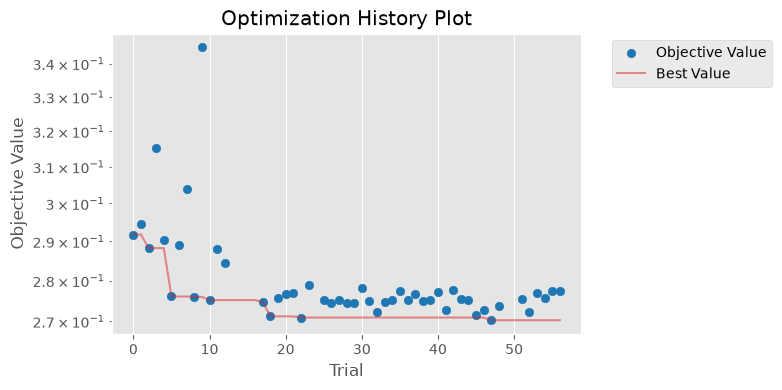

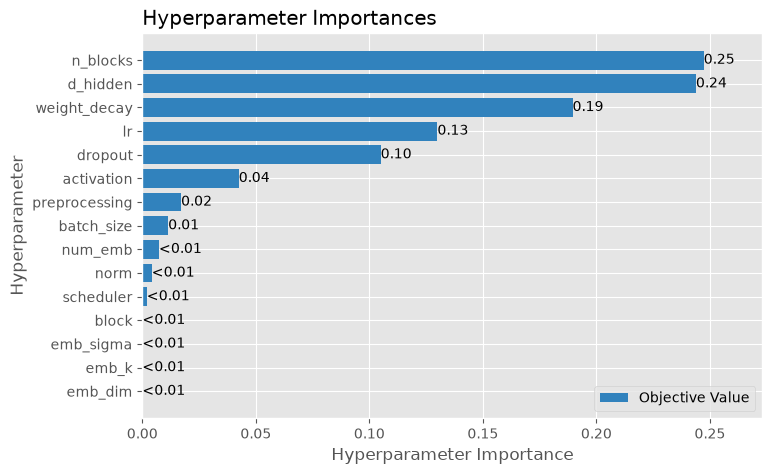

In [11]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
import warnings; warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)

plot_optimization_history(study); plt.gcf().set_size_inches(8, 4); plt.yscale('log'); plt.show()
plot_param_importances(study); plt.gcf().set_size_inches(8, 5); plt.show()

Топ-10 конфигураций

In [12]:
df_trials = study.trials_dataframe()
cols = ['number', 'value'] + [c for c in df_trials.columns if c.startswith('params_')] + ['user_attrs_n_params']
df_trials[df_trials.state == 'COMPLETE'].sort_values('value')[cols].head(10)

,number,value,params_activation,params_batch_size,params_block,params_d_hidden,params_dropout,params_emb_dim,params_emb_k,params_emb_sigma,params_lr,params_n_blocks,params_norm,params_num_emb,params_preprocessing,params_scheduler,params_weight_decay,user_attrs_n_params
47,47,0.270253,relu,512,resnet,410,0.324378,NaN,NaN,NaN,0.000293,6,layer,none,standard,constant,0.005911,4054901.0
22,22,0.270896,relu,512,resnet,410,0.151568,NaN,NaN,NaN,0.000493,5,layer,none,standard,constant,0.028717,3380451.0
18,18,0.271177,relu,512,resnet,488,0.237593,NaN,NaN,NaN,0.000908,5,layer,none,standard,constant,0.001148,4784841.0
45,45,0.271433,relu,512,resnet,466,0.257132,NaN,NaN,NaN,0.000541,5,layer,none,standard,constant,0.021658,4364091.0
32,32,0.272299,relu,512,resnet,415,0.223251,NaN,NaN,NaN,0.000262,5,layer,none,standard,constant,0.027941,3463176.0
52,52,0.272346,relu,512,resnet,316,0.225251,NaN,NaN,NaN,0.000355,5,layer,none,standard,constant,0.001564,2011341.0
46,46,0.272660,relu,512,resnet,390,0.284582,NaN,NaN,NaN,0.000367,6,layer,none,standard,constant,0.005949,3669901.0
41,41,0.272671,relu,128,resnet,490,0.148532,NaN,NaN,NaN,0.000109,6,layer,none,standard,constant,0.026841,5786901.0
48,48,0.273793,relu,512,resnet,504,0.203533,NaN,NaN,NaN,0.000330,6,layer,none,standard,constant,0.016377,6121585.0
26,26,0.274328,relu,512,resnet,237,0.090331,NaN,NaN,NaN,0.000406,4,layer,none,standard,constant,0.000525,908185.0


## 4. Шаг 6: архитектура от LLM

План:
1. Ячейка ниже формирует промпт: описание данных и задачи, статистики признаков по train, метрику, фиксированные условия обучения и формат ответа.
2. Ответ от Claude Opus 5.5 (класс сети и запись `ARCHS["v1"] = {...}`) идет в ячейку Итерация v1
3. Следующая ячейка обучит модель и напечатает обратную связь: val nRMSE, train nRMSE, лучшую эпоху, кривую по эпохам и историю всех итераций. Этот текст отправляется LLM и просится улучшение архитектуры
4. Повтор до версии 4

In [13]:
ARCHS = {}
LLM_LOG = RESULTS_DIR / ('llm_log_synthetic.csv' if SYNTHETIC else 'llm_log.csv')

y = split.y_train
feat = pd.DataFrame(split.X_train, columns=split.feature_names)
feat_table = pd.DataFrame({'mean': feat.mean(), 'std': feat.std(), 'min': feat.min(),
                           'median': feat.median(), 'max': feat.max(), 'n_unique': feat.nunique()}
                          ).to_markdown(floatfmt='.4g')

PROMPT = f"""Ты — эксперт по deep learning для табличных данных. Спроектируй архитектуру нейронной сети (PyTorch)
для задачи регрессии.

## Данные
Датасет elevators (OpenML task 361074, бенчмарк Grinsztajn et al., 2022): управление рулями высоты самолета F16,
нужно предсказать управляющее воздействие по состоянию самолета.
- объектов: train {len(split.y_train)}, validation {len(split.y_val)} (тестовая выборка отложена и недоступна)
- признаков: {split.X_train.shape[1]}, все числовые, пропусков и категориальных признаков нет
- таргет: вещественный, mean={y.mean():.4g}, std={y.std():.4g}, min={y.min():.4g}, max={y.max():.4g}

Статистики признаков (по train):
{feat_table}

## Метрика
nRMSE = RMSE / std(y) на валидации (чем меньше, тем лучше). Константный прогноз дает nRMSE ≈ 1.

## Условия обучения (фиксированы)
- предобработка признаков на выбор: "standard" (StandardScaler), "quantile" (QuantileTransformer → N(0,1)),
  "robust_sc" (robust scaling по медиане/IQR + плавное ограничение в (-3, 3));
- таргет стандартизуется по train, лосс MSE, оптимизатор AdamW, scheduler "constant" или "cosine";
- ранняя остановка по nRMSE на валидации, восстанавливается лучшая эпоха;
- GPU Tesla T4, одно обучение желательно не дольше нескольких минут.

## Формат ответа (строго)
Один блок Python-кода (torch, torch.nn as nn и torch.nn.functional as F уже импортированы):

```python
class NetV1(nn.Module):
    def __init__(self, n_features: int):
        ...
    def forward(self, x):          # x: (batch, n_features), float32 -> выход формы (batch,)
        ...

ARCHS["v1"] = {{
    "build": lambda n_features: NetV1(n_features),
    "train": {{"preprocessing": "...", "lr": ..., "weight_decay": ..., "batch_size": ...,
              "scheduler": "...", "max_epochs": ..., "patience": ...}},
    "comment": "кратко: идея архитектуры",
}}
```
После кода кратко объясни выбор."""

(RESULTS_DIR / 'llm_prompt.md').write_text(PROMPT, encoding='utf-8')
print(PROMPT)

Ты — эксперт по deep learning для табличных данных. Спроектируй архитектуру нейронной сети (PyTorch)
для задачи регрессии.

## Данные
Датасет elevators (OpenML task 361074, бенчмарк Grinsztajn et al., 2022): управление рулями высоты самолета F16,
нужно предсказать управляющее воздействие по состоянию самолета.
- объектов: train 9959, validation 3320 (тестовая выборка отложена и недоступна)
- признаков: 16, все числовые, пропусков и категориальных признаков нет
- таргет: вещественный, mean=0.0216, std=0.006715, min=0.012, max=0.078

Статистики признаков (по train):
|              |        mean |         std |       min |   median |      max |   n_unique |
|:-------------|------------:|------------:|----------:|---------:|---------:|-----------:|
| climbRate    | -13.84      | 276.5       | -945      | -32      | 973      |       1391 |
| Sgz          | -12.88      |  25.43      |  -97      | -13      |  94      |        177 |
| p            |  -0.01012   |   0.3095    |   -1.37   |   0 

In [14]:
def run_llm(name, seed=SEARCH_SEED):
    """Обучает ARCHS[name], пишет в лог и печатает текст обратной связи для LLM."""
    spec = ARCHS[name]
    res = train_model(spec['build'], split, spec['train'], seed=seed)
    tr, _ = evaluate_on(res, split.X_train, split.y_train, n_repeats=1)
    row = dict(name=name, val_nrmse=res.best_val, train_nrmse=tr, best_epoch=res.best_epoch,
               n_epochs=len(res.history['val_nrmse']), n_params=count_params(res.model),
               train_time=res.train_time, comment=spec.get('comment', ''))
    log = pd.read_csv(LLM_LOG) if LLM_LOG.exists() else pd.DataFrame()
    log = pd.concat([log[log.name != name] if len(log) else log, pd.DataFrame([row])], ignore_index=True)
    log.to_csv(LLM_LOG, index=False)

    curve = res.history['val_nrmse']
    step = max(1, len(curve) // 15)
    history = '\n'.join(f'- {r.name}: val nRMSE={r.val_nrmse:.4f}, train nRMSE={r.train_nrmse:.4f}, '
                        f'params={int(r.n_params):,}, {r.comment}' for r in log.itertuples())
    nxt = int(''.join(ch for ch in name if ch.isdigit()) or 0) + 1
    fb = f"""Результат итерации {name} на валидационной выборке:
- val nRMSE = {res.best_val:.4f}  (train nRMSE = {tr:.4f}); лучшая эпоха {res.best_epoch}, всего эпох {len(curve)} до ранней остановки
- параметров: {row['n_params']:,}; время обучения: {res.train_time:.1f} с
- val nRMSE по эпохам (каждая {step}-я): {', '.join(f'{v:.3f}' for v in curve[::step])}

История всех итераций:
{history}

Предложи модифицированную архитектуру (и при необходимости параметры обучения), которая уменьшит val nRMSE.
Опиши, какую проблему ты видишь в текущих результатах и что меняешь. Формат ответа тот же,
имя класса NetV{nxt}, ключ ARCHS["v{nxt}"]."""
    (RESULTS_DIR / f'llm_feedback_{name}.md').write_text(fb, encoding='utf-8')
    print(fb)

### Итерация v1

Обучение стартует с линейной регрессии, а нелинейная часть добавляет только то, что улучшает валидацию

Sa и SaTime1–4 почти дублируют друг друга. Поэлементный множитель на входе даёт сети дешёвый способ ослабить лишние признаки

robust_sc. У climbRate и diffClb тяжелые хвосты, а у diffSaTime* мало уникальных значений. Robust scaling с мягким клиппингом сохраняет монотонность и не разрывает близкие значения, в отличие от quantile на дискретных признаках

Модель легкая (0.5M параметров). При batch 256 это ~39 шагов на эпоху, так что 200 эпох с cosine-расписанием на T4 займут 1–2 минуты. Patience 30 подстраховывает от раннего обрыва на плато.

Чего не гарантирую: periodic/PLR-эмбеддинги сюда сознательно не добавлены. Таргет, судя по всему, гладкий, и они могут как помочь, так и переобучиться. Это естественный кандидат для v2, если v1 упрется в плато.

In [15]:
class _ResBlock(nn.Module):
    def __init__(self, d: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 2 * d)
        self.fc2 = nn.Linear(2 * d, d)
        self.drop = nn.Dropout(dropout)

    def forward(self, h):
        z = self.fc1(self.norm(h))
        z = F.silu(z)
        z = self.drop(z)
        z = self.fc2(z)
        return h + self.drop(z)


class NetV1(nn.Module):
    def __init__(self, n_features: int, d: int = 192, n_blocks: int = 3, dropout: float = 0.1):
        super().__init__()
        # обучаемый масштаб каждого признака (по мотивам scaling layer из RealMLP):
        # сеть сама «приглушает» шумные/дублирующие признаки (Sa, SaTime1..4)
        self.feat_scale = nn.Parameter(torch.ones(n_features))
        # линейная ветка: сильная базовая зависимость таргета от состояния
        self.linear = nn.Linear(n_features, 1)
        # нелинейная ветка: residual MLP
        self.inp = nn.Linear(n_features, d)
        self.blocks = nn.ModuleList([_ResBlock(d, dropout) for _ in range(n_blocks)])
        self.out_norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, 1)
        nn.init.zeros_(self.head.weight)  # старт = линейная модель, MLP добавляет поправку
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        x = x * self.feat_scale
        h = self.inp(x)
        for blk in self.blocks:
            h = blk(h)
        h = F.silu(self.out_norm(h))
        y = self.linear(x) + self.head(h)
        return y.squeeze(-1)


ARCHS["v1"] = {
    "build": lambda n_features: NetV1(n_features),
    "train": {"preprocessing": "robust_sc", "lr": 1e-3, "weight_decay": 1e-4, "batch_size": 256,
              "scheduler": "cosine", "max_epochs": 200, "patience": 30},
    "comment": "linear skip + residual MLP (3 pre-LN блока, d=192, SiLU, dropout 0.1) "
               "с обучаемым масштабом признаков; старт с линейной модели",
}

In [16]:
run_llm("v1")

Результат итерации v1 на валидационной выборке:
- val nRMSE = 0.2747  (train nRMSE = 0.2712); лучшая эпоха 37, всего эпох 68 до ранней остановки
- параметров: 449,122; время обучения: 29.8 с
- val nRMSE по эпохам (каждая 4-я): 0.422, 0.316, 0.328, 0.317, 0.290, 0.307, 0.284, 0.297, 0.286, 0.297, 0.292, 0.281, 0.282, 0.278, 0.287, 0.286, 0.284

История всех итераций:
- v1: val nRMSE=0.2747, train nRMSE=0.2712, params=449,122, linear skip + residual MLP (3 pre-LN блока, d=192, SiLU, dropout 0.1) с обучаемым масштабом признаков; старт с линейной модели

Предложи модифицированную архитектуру (и при необходимости параметры обучения), которая уменьшит val nRMSE.
Опиши, какую проблему ты видишь в текущих результатах и что меняешь. Формат ответа тот же,
имя класса NetV2, ключ ARCHS["v2"].


### Итерация v2

Какие проблемы я вижу в v1

Расписание LR не отработало. Cosine был рассчитан на 200 эпох, а ранняя остановка сработала на 68-й. К этому моменту LR оставался ~75% от исходного, то есть фаза дообучения при малом LR так и не наступила. Мешает шум оптимизации, а не переобучение

Модели не хватает выразительности, переобучения нет. Разрыв train/val маленький (0.271 против 0.275), и train тоже высокий. Регуляризацию усиливать бессмысленно, нужна выразительность.

Что меняю

Расписание обучения. max_epochs=120 и patience=120, то есть cosine проходит полностью до LR≈0, а лучшая эпоха все равно восстанавливается. LR снижен до 5e-4, чтобы уменьшить пилу. По времени это ~20–30 с.

PLR-эмбеддинги. Они дают MLP высокочастотные базисные функции по каждому признаку. Сырые признаки и линейная ветка сохранены, поэтому гладкая часть зависимости не теряется. σ=0.1 намеренно маленький: таргет выглядит гладким, а большие частоты легко переобучаются.

Dropout 0.1 → 0.05. Признаков переобучения нет.

In [17]:
class _ResBlockV2(nn.Module):
    def __init__(self, d: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 2 * d)
        self.fc2 = nn.Linear(2 * d, d)
        self.drop = nn.Dropout(dropout)

    def forward(self, h):
        z = self.fc2(self.drop(F.silu(self.fc1(self.norm(h)))))
        return h + self.drop(z)


class NetV2(nn.Module):
    def __init__(self, n_features: int, d: int = 192, n_blocks: int = 3, dropout: float = 0.05,
                 n_freq: int = 16, d_emb: int = 16, sigma: float = 0.1):
        super().__init__()
        self.feat_scale = nn.Parameter(torch.ones(n_features))
        self.linear = nn.Linear(n_features, 1)

        # periodic embeddings (PLR): x_j -> [cos, sin](2π·c_j·x_j) -> Linear_j -> ReLU
        self.freq = nn.Parameter(torch.randn(n_features, n_freq) * sigma)
        self.emb_w = nn.Parameter(torch.empty(n_features, 2 * n_freq, d_emb))
        self.emb_b = nn.Parameter(torch.zeros(n_features, d_emb))
        nn.init.kaiming_uniform_(self.emb_w.view(n_features * 2 * n_freq, d_emb).T, a=5 ** 0.5)

        self.inp = nn.Linear(n_features * d_emb + n_features, d)  # эмбеддинги + сырые признаки
        self.blocks = nn.ModuleList([_ResBlockV2(d, dropout) for _ in range(n_blocks)])
        self.out_norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        x = x * self.feat_scale                                   # (B, F)
        v = 6.283185307179586 * x.unsqueeze(-1) * self.freq       # (B, F, K)
        e = torch.cat([torch.cos(v), torch.sin(v)], dim=-1)       # (B, F, 2K)
        e = F.relu(torch.einsum("bfk,fkd->bfd", e, self.emb_w) + self.emb_b)  # (B, F, d_emb)
        h = self.inp(torch.cat([e.flatten(1), x], dim=1))
        for blk in self.blocks:
            h = blk(h)
        h = F.silu(self.out_norm(h))
        return (self.linear(x) + self.head(h)).squeeze(-1)


ARCHS["v2"] = {
    "build": lambda n_features: NetV2(n_features),
    "train": {"preprocessing": "robust_sc", "lr": 5e-4, "weight_decay": 1e-4, "batch_size": 256,
              "scheduler": "cosine", "max_epochs": 120, "patience": 120},
    "comment": "v1 + PLR periodic embeddings (16 частот, σ=0.1, per-feature linear 32→16) "
               "параллельно с сырыми признаками; dropout 0.05; cosine доводится до конца",
}

In [18]:
run_llm("v2")

Результат итерации v2 на валидационной выборке:
- val nRMSE = 0.2707  (train nRMSE = 0.2586); лучшая эпоха 44, всего эпох 120 до ранней остановки
- параметров: 506,978; время обучения: 61.8 с
- val nRMSE по эпохам (каждая 8-я): 0.554, 0.315, 0.300, 0.273, 0.283, 0.275, 0.275, 0.281, 0.283, 0.282, 0.281, 0.280, 0.279, 0.281, 0.281

История всех итераций:
- v1: val nRMSE=0.2747, train nRMSE=0.2712, params=449,122, linear skip + residual MLP (3 pre-LN блока, d=192, SiLU, dropout 0.1) с обучаемым масштабом признаков; старт с линейной модели
- v2: val nRMSE=0.2707, train nRMSE=0.2586, params=506,978, v1 + PLR periodic embeddings (16 частот, σ=0.1, per-feature linear 32→16) параллельно с сырыми признаками; dropout 0.05; cosine доводится до конца

Предложи модифицированную архитектуру (и при необходимости параметры обучения), которая уменьшит val nRMSE.
Опиши, какую проблему ты видишь в текущих результатах и что меняешь. Формат ответа тот же,
имя класса NetV3, ключ ARCHS["v3"].


### Итерация v3


Какие проблемы я вижу в v2

Дрейф после лучшей эпохи — это дисперсия. Лучший результат 0.271 был на 44-й эпохе, дальше val медленно уполз к 0.279–0.283, хотя LR уже уходил в ноль. На train ошибка падает, на val растет. Модель начинает подгонять шум, но выраженного переобучения нет.
Близко к шумовому потолку. Train nRMSE ≈ 0.259 и val ≈ 0.271 близки друг к другу. Похоже, у датасета заметный неустранимый шум. Точного потолка для elevators я не знаю, поэтому честно ожидаю выигрыш порядка тысячных, а не сотых.

Что меняю

Ансамбль вместо наращивания емкости. Наращивать емкость при таком раскладе бессмысленно, а ансамбль — самый надежный способ снизить дисперсию. TabM-mini дает 8 членов почти бесплатно по параметрам (+~25k): тело общее, у каждого члена свой ±1-адаптер на входе и своя голова.

Случайный член на объект при обучении. Лосс фиксирован (MSE по выходу формы (batch,)). Если бы я обучал среднее членов, они слиплись бы в одну модель. Случайный выбор члена на объект делает градиент несмещённой оценкой суммы их индивидуальных лоссов, поэтому разнообразие сохраняется.

Cosine на 80 эпох. Лучшая эпоха в v2 была примерно на 40% прогона, так что 120 эпох избыточны.

In [19]:
class _ResBlockV3(nn.Module):
    def __init__(self, d: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 2 * d)
        self.fc2 = nn.Linear(2 * d, d)
        self.drop = nn.Dropout(dropout)

    def forward(self, h):                      # h: (B, k, d) — Linear/LayerNorm работают по последней оси
        z = self.fc2(self.drop(F.silu(self.fc1(self.norm(h)))))
        return h + self.drop(z)


class NetV3(nn.Module):
    """v2 + неявный ансамбль из k членов в стиле TabM-mini (Gorishniy et al., 2024)."""
    def __init__(self, n_features: int, d: int = 192, n_blocks: int = 3, dropout: float = 0.05,
                 n_freq: int = 16, d_emb: int = 16, sigma: float = 0.1, k: int = 8):
        super().__init__()
        self.k = k
        self.feat_scale = nn.Parameter(torch.ones(n_features))
        self.linear = nn.Linear(n_features, 1)

        # PLR periodic embeddings (как в v2)
        self.freq = nn.Parameter(torch.randn(n_features, n_freq) * sigma)
        self.emb_w = nn.Parameter(torch.empty(n_features, 2 * n_freq, d_emb))
        self.emb_b = nn.Parameter(torch.zeros(n_features, d_emb))
        nn.init.kaiming_uniform_(self.emb_w.view(n_features * 2 * n_freq, d_emb).T, a=5 ** 0.5)

        d_in = n_features * d_emb + n_features
        # TabM-mini адаптер: у каждого члена ансамбля свой мультипликативный вектор на входе (init ±1)
        self.r = nn.Parameter(torch.randint(0, 2, (k, d_in)).float() * 2 - 1)

        self.inp = nn.Linear(d_in, d)          # общий для всех членов
        self.blocks = nn.ModuleList([_ResBlockV3(d, dropout) for _ in range(n_blocks)])
        self.out_norm = nn.LayerNorm(d)
        # отдельная голова у каждого члена
        self.head_w = nn.Parameter(torch.zeros(k, d))
        self.head_b = nn.Parameter(torch.zeros(k))

    def forward(self, x):
        x = x * self.feat_scale                                            # (B, F)
        v = 6.283185307179586 * x.unsqueeze(-1) * self.freq                # (B, F, K)
        e = torch.cat([torch.cos(v), torch.sin(v)], dim=-1)
        e = F.relu(torch.einsum("bfk,fkd->bfd", e, self.emb_w) + self.emb_b)
        z = torch.cat([e.flatten(1), x], dim=1)                            # (B, d_in)

        h = self.inp(z.unsqueeze(1) * self.r)                              # (B, k, d)
        for blk in self.blocks:
            h = blk(h)
        h = F.silu(self.out_norm(h))
        p = (h * self.head_w).sum(-1) + self.head_b + self.linear(x)       # (B, k)

        if self.training:
            # каждому объекту — случайный член ансамбля: MSE по выходу равна (в матожидании)
            # среднему MSE членов, т.е. члены обучаются как независимые модели, а не как одна
            idx = torch.randint(0, self.k, (p.shape[0], 1), device=p.device)
            return p.gather(1, idx).squeeze(1)
        return p.mean(1)                                                   # инференс: среднее k членов


ARCHS["v3"] = {
    "build": lambda n_features: NetV3(n_features),
    "train": {"preprocessing": "robust_sc", "lr": 5e-4, "weight_decay": 1e-4, "batch_size": 256,
              "scheduler": "cosine", "max_epochs": 80, "patience": 80},
    "comment": "v2 + TabM-mini: 8 членов с общим телом, свои ±1-адаптеры на входе и свои головы; "
               "в train случайный член на объект, на инференсе среднее; cosine на 80 эпох",
}

In [20]:
run_llm("v3")

Результат итерации v3 на валидационной выборке:
- val nRMSE = 0.2753  (train nRMSE = 0.2763); лучшая эпоха 69, всего эпох 80 до ранней остановки
- параметров: 510,505; время обучения: 233.9 с
- val nRMSE по эпохам (каждая 5-я): 0.714, 0.353, 0.322, 0.317, 0.297, 0.291, 0.285, 0.282, 0.282, 0.279, 0.278, 0.280, 0.277, 0.277, 0.276, 0.276

История всех итераций:
- v1: val nRMSE=0.2747, train nRMSE=0.2712, params=449,122, linear skip + residual MLP (3 pre-LN блока, d=192, SiLU, dropout 0.1) с обучаемым масштабом признаков; старт с линейной модели
- v2: val nRMSE=0.2707, train nRMSE=0.2586, params=506,978, v1 + PLR periodic embeddings (16 частот, σ=0.1, per-feature linear 32→16) параллельно с сырыми признаками; dropout 0.05; cosine доводится до конца
- v3: val nRMSE=0.2753, train nRMSE=0.2763, params=510,505, v2 + TabM-mini: 8 членов с общим телом, свои ±1-адаптеры на входе и свои головы; в train случайный член на объект, на инференсе среднее; cosine на 80 эпох

Предложи модифицированную а

### Итерация v4


Почему v3 не сработала (моя ошибка)

Это недообучение, а не переобучение. Train nRMSE (0.2763) оказался выше val, лучшая эпоха — 69-я из 80, кривая к концу еще снижалась.
Причина в способе обучения ансамбля. При выборе случайного члена на объект каждый член получал градиент только от ~1/8 батча, то есть ~32 объекта на шаг. Члены учились в 8 раз медленнее и шумнее, а cosine на 80 эпох погасил LR раньше, чем они сошлись. Выигрыш от снижения дисперсии этого не перекрыл.

Что меняю в v4

Лосс членов без деления данных. Целевой лосс прежний: средний MSE членов. Теперь каждый объект дает градиент всем 8 членам сразу. В train-режиме выход равен mean + s·std со случайным знаком s, и его MSE в матожидании точно равен среднему MSE членов (вывод в комментарии в коде). На инференсе выход — просто среднее.

Возврат к 120 эпохам cosine, как в v2, где сходимость была достаточной

In [21]:
class _ResBlockV4(nn.Module):
    def __init__(self, d: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 2 * d)
        self.fc2 = nn.Linear(2 * d, d)
        self.drop = nn.Dropout(dropout)

    def forward(self, h):                      # h: (B, k, d)
        z = self.fc2(self.drop(F.silu(self.fc1(self.norm(h)))))
        return h + self.drop(z)


class NetV4(nn.Module):
    """v3, но каждый объект обучает ВСЕХ членов ансамбля (лосс TabM через рандомизированный выход)."""
    def __init__(self, n_features: int, d: int = 192, n_blocks: int = 3, dropout: float = 0.05,
                 n_freq: int = 16, d_emb: int = 16, sigma: float = 0.1, k: int = 8):
        super().__init__()
        self.k = k
        self.feat_scale = nn.Parameter(torch.ones(n_features))
        self.linear = nn.Linear(n_features, 1)

        self.freq = nn.Parameter(torch.randn(n_features, n_freq) * sigma)
        self.emb_w = nn.Parameter(torch.empty(n_features, 2 * n_freq, d_emb))
        self.emb_b = nn.Parameter(torch.zeros(n_features, d_emb))
        nn.init.kaiming_uniform_(self.emb_w.view(n_features * 2 * n_freq, d_emb).T, a=5 ** 0.5)

        d_in = n_features * d_emb + n_features
        self.r = nn.Parameter(torch.randint(0, 2, (k, d_in)).float() * 2 - 1)

        self.inp = nn.Linear(d_in, d)
        self.blocks = nn.ModuleList([_ResBlockV4(d, dropout) for _ in range(n_blocks)])
        self.out_norm = nn.LayerNorm(d)
        self.head_w = nn.Parameter(torch.zeros(k, d))
        self.head_b = nn.Parameter(torch.zeros(k))

    def forward(self, x):
        x = x * self.feat_scale
        v = 6.283185307179586 * x.unsqueeze(-1) * self.freq
        e = torch.cat([torch.cos(v), torch.sin(v)], dim=-1)
        e = F.relu(torch.einsum("bfk,fkd->bfd", e, self.emb_w) + self.emb_b)
        z = torch.cat([e.flatten(1), x], dim=1)

        h = self.inp(z.unsqueeze(1) * self.r)                              # (B, k, d)
        for blk in self.blocks:
            h = blk(h)
        h = F.silu(self.out_norm(h))
        p = (h * self.head_w).sum(-1) + self.head_b + self.linear(x)       # (B, k)
        p_mean = p.mean(1)

        if self.training:
            # o = mean + s·std, s ∈ {±1}:  E_s[(o - y)^2] = (mean - y)^2 + var = mean_m (p_m - y)^2,
            # т.е. в матожидании это ровно лосс TabM (средний MSE членов), но градиент получают все k членов
            std = torch.sqrt(p.var(1, unbiased=False) + 1e-6)
            s = torch.randint(0, 2, p_mean.shape, device=p.device).float() * 2 - 1
            return p_mean + s * std
        return p_mean


ARCHS["v4"] = {
    "build": lambda n_features: NetV4(n_features),
    "train": {"preprocessing": "robust_sc", "lr": 5e-4, "weight_decay": 1e-4, "batch_size": 256,
              "scheduler": "cosine", "max_epochs": 120, "patience": 120},
    "comment": "v3 с исправленным обучением ансамбля: выход mean ± std (случайный знак) даёт лосс TabM "
               "без деления данных между членами; cosine на 120 эпох",
}

In [22]:
run_llm("v4")

Результат итерации v4 на валидационной выборке:
- val nRMSE = 0.2709  (train nRMSE = 0.2573); лучшая эпоха 95, всего эпох 120 до ранней остановки
- параметров: 510,505; время обучения: 337.9 с
- val nRMSE по эпохам (каждая 8-я): 0.632, 0.307, 0.296, 0.282, 0.278, 0.283, 0.274, 0.274, 0.274, 0.274, 0.271, 0.273, 0.274, 0.272, 0.272

История всех итераций:
- v1: val nRMSE=0.2747, train nRMSE=0.2712, params=449,122, linear skip + residual MLP (3 pre-LN блока, d=192, SiLU, dropout 0.1) с обучаемым масштабом признаков; старт с линейной модели
- v2: val nRMSE=0.2707, train nRMSE=0.2586, params=506,978, v1 + PLR periodic embeddings (16 частот, σ=0.1, per-feature linear 32→16) параллельно с сырыми признаками; dropout 0.05; cosine доводится до конца
- v3: val nRMSE=0.2753, train nRMSE=0.2763, params=510,505, v2 + TabM-mini: 8 членов с общим телом, свои ±1-адаптеры на входе и свои головы; в train случайный член на объект, на инференсе среднее; cosine на 80 эпох
- v4: val nRMSE=0.2709, train nRMS

История итераций LLM

,name,val_nrmse,train_nrmse,best_epoch,n_epochs,n_params,train_time,comment
0,v1,0.274664,0.271166,37,68,449122,29.781943,"linear skip + residual MLP (3 pre-LN блока, d=..."
1,v2,0.270749,0.258649,44,120,506978,61.834940,"v1 + PLR periodic embeddings (16 частот, σ=0.1..."
2,v3,0.275283,0.276347,69,80,510505,233.934518,"v2 + TabM-mini: 8 членов с общим телом, свои ±..."
3,v4,0.270901,0.257255,95,120,510505,337.886478,v3 с исправленным обучением ансамбля: выход me...


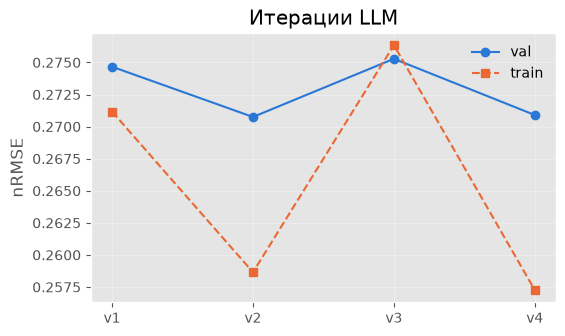

In [23]:
llm_log = pd.read_csv(LLM_LOG)
display(llm_log)
plt.figure(figsize=(6, 3.5))
plt.plot(llm_log.name, llm_log.val_nrmse, 'o-', label='val', color='#2a78d6')
plt.plot(llm_log.name, llm_log.train_nrmse, 's--', label='train', color='#eb6834')
plt.ylabel('nRMSE'); plt.title('Итерации LLM'); plt.legend(frameon=False); plt.grid(alpha=.3); plt.show()

За 4 итерации val nRMSE снизился с 0.275 (v1) до 0.271 (v2 и v4). Это сопоставимо с лучшей конфигурацией Optuna (0.270), полученной за 57 триалов, и с RealMLP из статьи (0.276–0.280). LLM вышла на тот же уровень качества за число обучений на порядок меньше.

Улучшение не монотонное:
* **v1** — residual MLP (3 блока с LayerNorm, ширина 192, SiLU, dropout 0.1) с параллельной линейной веткой и обучаемым масштабом признаков: обучение стартует с линейной регрессии, а нелинейная часть добавляет только то, что улучшает валидацию.
* **v1 → v2 (0.275 → 0.271):** добавлены периодические PLR-эмбеддинги признаков (16 частот, σ = 0.1) параллельно с исходными признаками, dropout снижен до 0.05, косинусное расписание lr доводится до конца. Val заметно улучшился.
* **v2 → v3 (0.271 → 0.275):** добавлен ансамбль TabM-mini — 8 членов с общим телом, у каждого свой адаптер на входе и своя голова; при обучении на каждый объект случайно выбирался один член, на инференсе выходы усреднялись. Это шаг назад: train nRMSE вырос до уровня val (0.2763 против 0.2753), то есть модель недообучилась. Причина — в схеме обучения ансамбля: каждый член получал градиент только от ~1/8 батча, учился в 8 раз медленнее и не успел сойтись за 80 эпох.
* **v3 → v4 (0.275 → 0.271):** по обратной связи LLM сама диагностировала недообучение и сохранила ансамбль, но исправила его обучение: выход при обучении равен среднему членов ± их разброс со случайным знаком. Матожидание такого MSE равно среднему MSE членов, поэтому каждый объект обучает все 8 членов сразу. Плюс возврат к 120 эпохам. Результат вернулся на уровень v2 (0.2709 против 0.2707), но не превзошел его, поэтому лучшей по валидации осталась v2.

У v2 и v4 разрыв между train и val около 0.012–0.014, то есть небольшое переобучение при лучшем качестве на валидации.

Каждая итерация обучалась с одним seed, а различия между v2, v4 и Optuna составляют тысячные доли. Это сопоставимо с разбросом от инициализации. Значимость различий проверяется на шаге 7, где v1 и v2 обучаются с 10 seed и сравниваются по доверительным интервалам на тестовой выборке.

## 5. Шаг 7: сравнение на контрольной выборке

Каждая архитектура обучается 10 раз с разными seed на фиксированном сплите. Для каждой считаем:
* test nRMSE: среднее и 95% доверительный интервал по t-распределению (как в статье, App. C.6): `mean ± t_{0.975, n-1} · s / √n`;
* время обучения (весь цикл до ранней остановки) и время инференса (мс на 1000 объектов, вместе с предобработкой);
* число обучаемых параметров;
* кривые обучения: test и val nRMSE по эпохам, все архитектуры на одном графике.

Участники:
* **Optuna**: лучшая конфигурация из §3;
* **LLM-v1 и LLM-лучшая**: первая итерация и лучшая по валидации;
* **MLP-D (статья)**: архитектура и гиперпараметры по табл. C.4; предобработка — обычный QuantileTransformer (в статье — RTDL quantile с добавлением шума);
* опционально **RealMLP-TD и CatBoost-TD** из библиотеки авторов `pytabkit` на **нашем** сплите: самое точное сравнение со статьёй.

In [24]:
SEEDS = list(range(10))
USE_PYTABKIT = True          # RealMLP-TD / CatBoost-TD из pytabkit; поставьте False, чтобы не сравнивать с ними

In [25]:
class PaperMLPD(nn.Module):
    """MLP-D из статьи (табл. C.4)."""
    def __init__(self, n_features):
        super().__init__()
        dims, layers = [n_features, 128, 256, 128], []
        for a, b in zip(dims[:-1], dims[1:]):
            layers += [nn.Linear(a, b), nn.ReLU(), nn.Dropout(0.1)]
        self.net = nn.Sequential(*layers, nn.Linear(128, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


llm_log = pd.read_csv(LLM_LOG) if LLM_LOG.exists() else pd.DataFrame(columns=['name', 'val_nrmse'])
llm_names = list(dict.fromkeys([n for n in ['v1', llm_log.sort_values('val_nrmse').name.iloc[0]
                                            if len(llm_log) else None] if n in ARCHS]))

CANDIDATES = [dict(name='Optuna', build=lambda n: TabMLP(n, OPTUNA_ARCH), train=OPTUNA_TRAIN)]
CANDIDATES += [dict(name=f'LLM-{nm}', build=ARCHS[nm]['build'], train=ARCHS[nm]['train']) for nm in llm_names]
CANDIDATES += [dict(name='MLP-D (статья)', build=lambda n: PaperMLPD(n),
                    train=dict(preprocessing='quantile', lr=1e-3, weight_decay=0.01, batch_size=128,
                               max_epochs=1000, patience=20))]
print('участники:', [c['name'] for c in CANDIDATES])

участники: ['Optuna', 'LLM-v1', 'LLM-v2', 'MLP-D (статья)']


In [26]:
import logging, warnings
try:
    import pytabkit, pytorch_lightning   # импорт до настройки логгеров: lightning при импорте ставит уровень INFO
except ImportError:
    pass
for _n in ('lightning', 'lightning.pytorch', 'pytorch_lightning', 'lightning_fabric'):
    logging.getLogger(_n).setLevel(logging.ERROR)   # убираем служебный вывод pytorch-lightning из pytabkit
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)


def run_pytabkit(name, sp, seed):
    import pytabkit
    cls = {'RealMLP-TD': pytabkit.RealMLP_TD_Regressor, 'CatBoost-TD': pytabkit.CatBoost_TD_Regressor}[name]
    kw = dict(random_state=seed, n_cv=1, n_refit=0, verbosity=0)
    if name == 'RealMLP-TD':
        kw['device'] = str(DEVICE)
    m = cls(**kw)
    t0 = time.perf_counter(); m.fit(sp.X_train, sp.y_train, sp.X_val, sp.y_val); tt = time.perf_counter() - t0
    times = []
    for _ in range(5):
        t1 = time.perf_counter(); p = np.asarray(m.predict(sp.X_test)).reshape(-1); times.append(time.perf_counter() - t1)
    pv = np.asarray(m.predict(sp.X_val)).reshape(-1)
    n_params = np.nan
    if name == 'RealMLP-TD':      # параметры ищем среди torch-модулей внутри обёртки
        try:
            n_params = count_params(m.cv_alg_interface_.model)
        except AttributeError:
            pass
    return dict(name=f'{name} (pytabkit)', seed=seed, test_nrmse=nrmse(sp.y_test, p, sp.y_scale),
                val_nrmse=nrmse(sp.y_val, pv, sp.y_scale), train_time=tt,
                infer_ms_per_1k=float(np.median(times)) / len(sp.y_test) * 1e6, n_params=n_params)


def run_all(protocol='fixed'):
    """protocol='fixed' — фиксированный сплит, меняется seed (требование лабы);
       protocol='paper' — для seed s новый случайный сплит 60/20/20 (как 10 сплитов в статье)."""
    runs = []
    for seed in SEEDS:
        sp = split if protocol == 'fixed' else make_split(seed)
        for c in CANDIDATES:
            res = train_model(c['build'], sp, c['train'], seed=seed, track_test=True)
            test, infer = evaluate_on(res, sp.X_test, sp.y_test)
            h = res.history
            runs.append(dict(name=c['name'], seed=seed, test_nrmse=test, val_nrmse=res.best_val,
                             train_time=res.train_time, infer_ms_per_1k=infer, n_params=count_params(res.model),
                             curve_val=h['val_nrmse'], curve_test=h['test_nrmse'], curve_time=h['time']))
            print(f"[seed {seed}] {c['name']:<16} test={test:.4f}  val={res.best_val:.4f}  "
                  f"{res.train_time:5.1f}s  {count_params(res.model):,} params")
        if USE_PYTABKIT:
            for nm in ('RealMLP-TD', 'CatBoost-TD'):
                try:
                    r = run_pytabkit(nm, sp, seed); runs.append(r)
                    print(f"[seed {seed}] {r['name']:<16} test={r['test_nrmse']:.4f}  {r['train_time']:5.1f}s")
                except Exception as e:
                    print(f'{nm}: пропущено ({e!r})')
    return runs


RUNS = run_all('fixed')

(RESULTS_DIR / 'eval_runs_fixed.json').write_text(json.dumps(RUNS))

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[seed 0] Optuna           test=0.2807  val=0.2763  115.2s  4,054,901 params
[seed 0] LLM-v1           test=0.2833  val=0.2793   26.7s  449,122 params
[seed 0] LLM-v2           test=0.2759  val=0.2746   58.7s  506,978 params
[seed 0] MLP-D (статья)   test=0.2958  val=0.2832    7.7s  68,225 params
[seed 0] RealMLP-TD (pytabkit) test=0.2748   72.3s
[seed 0] CatBoost-TD (pytabkit) test=0.3227    5.9s
[seed 1] Optuna           test=0.2819  val=0.2741  136.3s  4,054,901 params
[seed 1] LLM-v1           test=0.2830  val=0.2780   30.6s  449,122 params
[seed 1] LLM-v2           test=0.2791  val=0.2712   60.1s  506,978 params
[seed 1] MLP-D (статья)   test=0.2948  val=0.2858    7.5s  68,225 params
[seed 1] RealMLP-TD (pytabkit) test=0.2760   72.2s
[seed 1] CatBoost-TD (pytabkit) test=0.3248    6.7s
[seed 2] Optuna           test=0.2805  val=0.2752  127.4s  4,054,901 params
[seed 2] LLM-v1           test=0.2845  val=0.2793   24.1s  449,122 params
[seed 2] LLM-v2           test=0.2832  val=0.2734 

198745

### Итоговая таблица

Доверительный интервал (`±`) — полуширина 95% ДИ для среднего по 10 seed.

In [27]:
from scipy.stats import t as student_t

# Результаты статьи для elevators (табл. D.11–D.12: nRMSE, среднее ± 95% ДИ по 10 сплитам)
PAPER = {'RealMLP-HPO': (0.276, 0.005), 'RealMLP-TD': (0.280, 0.005), 'TabR-HPO': (0.285, 0.005),
         'CatBoost-HPO': (0.308, 0.007), 'MLP-PLR-HPO': (0.315, 0.013), 'ResNet-HPO': (0.318, 0.007),
         'LGBM-HPO': (0.319, 0.005), 'CatBoost-TD': (0.323, 0.006), 'XGB-HPO': (0.328, 0.008),
         'RF-D': (0.420, 0.011), 'MLP-PLR-D': (0.667, 0.138), 'MLP-HPO': (0.744, 0.017), 'MLP-D': (0.745, 0.014)}


def ci95(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return student_t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan


def summarize(runs):
    df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith('curve')} for r in runs])
    rows = []
    for name, g in df.groupby('name', sort=False):
        row = {'архитектура': name, 'seeds': len(g)}
        for col, lab, d in [('test_nrmse', 'test nRMSE', 4), ('val_nrmse', 'val nRMSE', 4),
                            ('train_time', 'обучение, с', 1), ('infer_ms_per_1k', 'инференс, мс/1k', 3)]:
            vals = pd.to_numeric(g.get(col), errors='coerce')
            row[lab] = f'{vals.mean():.{d}f} ± {ci95(vals):.{d}f}' if vals is not None and vals.notna().any() else '—'
        p = pd.to_numeric(g['n_params'], errors='coerce').median() if 'n_params' in g else np.nan
        row['параметров'] = f'{int(p):,}'.replace(',', ' ') if pd.notna(p) else '—'
        row['_sort'] = g['test_nrmse'].mean()
        rows.append(row)
    return pd.DataFrame(rows).sort_values('_sort').drop(columns='_sort').reset_index(drop=True)


SUMMARY = summarize(RUNS)
SUMMARY.to_csv(RESULTS_DIR / 'summary_fixed.csv', index=False)
display(SUMMARY)
display(pd.DataFrame([{'модель (статья)': k, 'test nRMSE': f'{m:.3f} ± {c:.3f}'} for k, (m, c) in PAPER.items()]))

,архитектура,seeds,test nRMSE,val nRMSE,"обучение, с","инференс, мс/1k",параметров
0,RealMLP-TD (pytabkit),10,0.2759 ± 0.0015,0.2716 ± 0.0007,72.1 ± 0.3,8.626 ± 0.438,150 641
1,LLM-v2,10,0.2778 ± 0.0019,0.2723 ± 0.0018,58.9 ± 0.4,6.351 ± 0.080,506 978
2,Optuna,10,0.2824 ± 0.0020,0.2758 ± 0.0015,129.7 ± 20.9,37.772 ± 0.913,4 054 901
3,LLM-v1,10,0.2827 ± 0.0015,0.2780 ± 0.0015,30.5 ± 4.1,4.585 ± 0.609,449 122
4,MLP-D (статья),10,0.2918 ± 0.0019,0.2844 ± 0.0019,7.9 ± 0.7,3.784 ± 0.138,68 225
5,CatBoost-TD (pytabkit),10,0.3253 ± 0.0009,0.3219 ± 0.0011,5.9 ± 0.4,2.311 ± 0.188,—


,модель (статья),test nRMSE
0,RealMLP-HPO,0.276 ± 0.005
1,RealMLP-TD,0.280 ± 0.005
2,TabR-HPO,0.285 ± 0.005
3,CatBoost-HPO,0.308 ± 0.007
4,MLP-PLR-HPO,0.315 ± 0.013
5,ResNet-HPO,0.318 ± 0.007
6,LGBM-HPO,0.319 ± 0.005
7,CatBoost-TD,0.323 ± 0.006
8,XGB-HPO,0.328 ± 0.008
9,RF-D,0.420 ± 0.011


* Лучший результат у RealMLP-TD: test nRMSE 0.2759 ± 0.0015. С LLM-v2 (0.2778 ± 0.0019) отличие незначимо: доверительные интервалы пересекаются. От остальных моделей LLM-v2 отличается значимо.
* Optuna (0.2824 ± 0.0020) и LLM-v1 (0.2827 ± 0.0015) статистически неразличимы: доверительные интервалы пересекаются. Два разных способа поиска архитектуры пришли к одному уровню качества.
* MLP-D (0.2918) хуже всех найденных архитектур, то есть поиск дал реальный выигрыш. CatBoost-TD (0.3253) хуже всех нейросетей.
* Test nRMSE у всех моделей на 0.003–0.007 выше val: это оптимизм от выбора лучшей эпохи и конфигурации по валидации. Порядок моделей на val и test совпадает, значит валидация надёжно отражает качество.
* Качество слабо связано с числом параметров. У Optuna самая большая сеть (4,1 млн параметров), но она уступает LLM-v2 (0,5 млн) и RealMLP-TD (0,15 млн). Среди нейросетей самый быстрый инференс у MLP-D (3,8 мс на 1000 объектов). LLM-v2 — лучшее качество среди найденных архитектур при умеренных затратах (59 с обучения).

* Сравнение со статьей. Наши RealMLP-TD (0.276) и CatBoost-TD (0.325) совпадают с цифрами статьи (0.280 ± 0.005 и 0.323 ± 0.006) в пределах погрешности, значит протокол воспроизведен корректно. Лучшие наши архитектуры находятся на уровне лучших моделей статьи с подбором гиперпараметров (RealMLP-HPO 0.276, TabR-HPO 0.285). Провал MLP-D из статьи (0.745) не воспроизвелся: у нас 0.292 при той же архитектуре. Оговорка: в статье результаты усреднены по 10 разным сплитам, а здесь сплит один. Прямое сравнение — в таблице с протоколом статьи ниже.

### Кривые обучения

Сплошная линия — test nRMSE, пунктир — val nRMSE (среднее по seed), полоса — 95% ДИ. Слева по эпохам, справа по времени обучения. Горизонтальные линии показывают RealMLP-TD и CatBoost-TD из статьи.

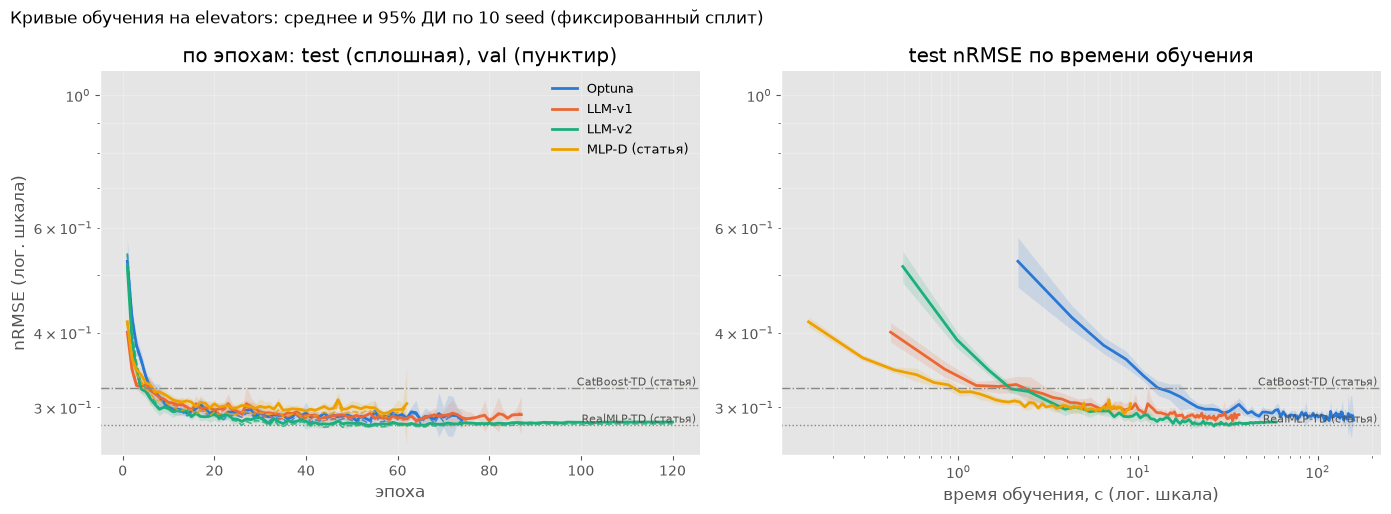

In [28]:
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']


def mean_band(curves, min_alive=3):
    L = max(len(c) for c in curves)
    M_ = np.full((len(curves), L), np.nan)
    for i, c in enumerate(curves):
        M_[i, :len(c)] = c
    alive = np.isfinite(M_).sum(0)
    keep = np.where(alive >= min(min_alive, len(curves)))[0]
    mean = np.nanmean(M_[:, keep], 0)
    ci = np.array([ci95(M_[:, j]) if alive[j] > 1 else 0 for j in keep])
    return keep + 1, mean, np.nan_to_num(ci)


def plot_curves(runs, title):
    names = list(dict.fromkeys(r['name'] for r in runs if r.get('curve_test')))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    for i, nm in enumerate(names):
        col = COLORS[i % len(COLORS)]
        rs = [r for r in runs if r['name'] == nm and r.get('curve_test')]
        x, m, ci = mean_band([r['curve_test'] for r in rs])
        xv, mv, _ = mean_band([r['curve_val'] for r in rs])
        ep_t = np.nanmean([np.diff([0.0] + list(r['curve_time'])).mean() for r in rs])
        axes[0].plot(x, m, color=col, lw=2, label=nm)
        axes[0].fill_between(x, np.maximum(m - ci, 1e-3), m + ci, color=col, alpha=.15, lw=0)
        axes[0].plot(xv, mv, color=col, lw=1.2, ls='--', alpha=.8)
        axes[1].plot(x * ep_t, m, color=col, lw=2, label=nm)
        axes[1].fill_between(x * ep_t, np.maximum(m - ci, 1e-3), m + ci, color=col, alpha=.15, lw=0)
    for ax in axes:
        for k, ls in [('RealMLP-TD', ':'), ('CatBoost-TD', '-.')]:
            ax.axhline(PAPER[k][0], color='#898781', lw=1, ls=ls)
            ax.text(1.0, PAPER[k][0], f'{k} (статья) ', transform=ax.get_yaxis_transform(),
                    ha='right', va='bottom', fontsize=8, color='#52514e')
        ax.set_yscale('log'); ax.set_ylim(top=1.1); ax.grid(True, which='both', alpha=.25)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    axes[0].set(xlabel='эпоха', ylabel='nRMSE (лог. шкала)', title='по эпохам: test (сплошная), val (пунктир)')
    axes[1].set(xlabel='время обучения, с (лог. шкала)', title='test nRMSE по времени обучения')
    axes[1].set_xscale('log'); axes[0].legend(frameon=False, fontsize=9)
    fig.suptitle(title, x=0.01, ha='left'); fig.tight_layout()
    return fig


fig = plot_curves(RUNS, 'Кривые обучения на elevators: среднее и 95% ДИ по 10 seed (фиксированный сплит)')
fig.savefig(RESULTS_DIR / 'learning_curves_fixed.png', dpi=160, bbox_inches='tight'); plt.show()

Все модели быстро сходятся: за первые 10–20 эпох test nRMSE падает примерно до 0.30, дальше идет медленное улучшение. LLM-v2 обучается дольше всех (до 120 эпох) и продолжает улучшаться, когда остальные уже остановились. Поэтому она и лучшая из найденных архитектур. Ранняя остановка у остальных моделей срабатывает на 60–90 эпохах. Пунктир (val) идет чуть ниже сплошной линии (test) у всех моделей. Это ожидаемо, потому что выбор эпохи и конфигурации делался по валидации.

По времени: MLP-D быстрее всех доходит до уровня 0.30 (за 1 с), LLM-v1 примерно за 5 с. Optuna и LLM-v2 стартуют с худшего значения (сеть больше, первые эпохи хуже). LLM-v2 обгоняет их к 4–5 с, а Optuna выходит на их уровень только к 20–30 с.

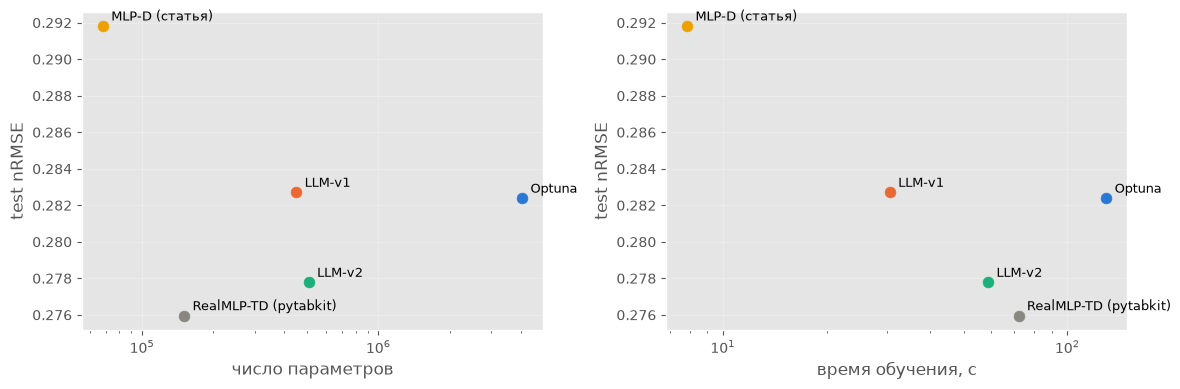

In [29]:
df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith('curve')} for r in RUNS])
agg = df.groupby('name', sort=False).agg(test=('test_nrmse', 'mean'), params=('n_params', 'median'),
                                          t=('train_time', 'mean')).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, lab in [(axes[0], 'params', 'число параметров'), (axes[1], 't', 'время обучения, с')]:
    for i, (nm, r) in enumerate(agg.iterrows()):
        names = list(dict.fromkeys(r['name'] for r in RUNS if r.get('curve_test')))
        c = COLORS[names.index(nm) % len(COLORS)] if nm in names else '#898781'
        ax.scatter(r[col], r.test, s=60, color=c, zorder=3)
        ax.annotate(nm, (r[col], r.test), xytext=(6, 4), textcoords='offset points', fontsize=9)
    ax.set(xscale='log', xlabel=lab, ylabel='test nRMSE'); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

Качество слабо связано с размером сети. Optuna нашла самую большую модель (4,1 млн параметров), но она уступает LLM-v2 (0,5 млн) и RealMLP-TD (0,15 млн). Лучший компромисс дает LLM-v2: качество на уровне RealMLP-TD при умеренном размере и 59 с обучения. RealMLP-TD чуть точнее при меньшем числе параметров, но обучается дольше (72 с). LLM-v1 обучается быстро (31 с, быстрее только MLP-D), а Optuna дольше всех (130 с)

### Протокол статьи: 10 случайных сплитов

Для каждого seed берется новый сплит 60/20/20, как в табл. D.11–D.12. Так получается прямое сравнение с цифрами статьи.

In [30]:
RUNS_PAPER = run_all('paper')
(RESULTS_DIR / 'eval_runs_paper.json').write_text(json.dumps(RUNS_PAPER))
display(summarize(RUNS_PAPER).drop(columns=['инференс, мс/1k']))

[seed 0] Optuna           test=0.2807  val=0.2763  113.1s  4,054,901 params
[seed 0] LLM-v1           test=0.2833  val=0.2793   26.4s  449,122 params
[seed 0] LLM-v2           test=0.2759  val=0.2746   58.8s  506,978 params
[seed 0] MLP-D (статья)   test=0.2958  val=0.2832    7.8s  68,225 params
[seed 0] RealMLP-TD (pytabkit) test=0.2748   72.0s
[seed 0] CatBoost-TD (pytabkit) test=0.3227    5.2s
[seed 1] Optuna           test=0.2813  val=0.2857  123.7s  4,054,901 params
[seed 1] LLM-v1           test=0.2828  val=0.2897   24.9s  449,122 params
[seed 1] LLM-v2           test=0.2827  val=0.2795   59.3s  506,978 params
[seed 1] MLP-D (статья)   test=0.2864  val=0.2982    8.3s  68,225 params
[seed 1] RealMLP-TD (pytabkit) test=0.2759   72.2s
[seed 1] CatBoost-TD (pytabkit) test=0.3194    5.4s
[seed 2] Optuna           test=0.2732  val=0.2748  104.5s  4,054,901 params
[seed 2] LLM-v1           test=0.2889  val=0.2755   51.3s  449,122 params
[seed 2] LLM-v2           test=0.2737  val=0.2690 

,архитектура,seeds,test nRMSE,val nRMSE,"обучение, с",параметров
0,RealMLP-TD (pytabkit),10,0.2814 ± 0.0037,0.2777 ± 0.0036,71.9 ± 0.2,150 641
1,LLM-v2,10,0.2820 ± 0.0037,0.2757 ± 0.0031,58.9 ± 0.2,506 978
2,Optuna,10,0.2856 ± 0.0046,0.2802 ± 0.0033,124.6 ± 18.6,4 054 901
3,LLM-v1,10,0.2901 ± 0.0041,0.2832 ± 0.0041,32.8 ± 6.5,449 122
4,MLP-D (статья),10,0.3000 ± 0.0070,0.2916 ± 0.0047,8.0 ± 0.8,68 225
5,CatBoost-TD (pytabkit),10,0.3226 ± 0.0049,0.3208 ± 0.0035,5.9 ± 0.5,—


На 10 случайных сплитах порядок моделей сохранился:

RealMLP-TD (0.2814 ± 0.0037)

LLM-v2 (0.2820 ± 0.0037)

Optuna (0.2856)

LLM-v1 (0.2901)

MLP-D (0.3000)

CatBoost-TD (0.3226)

Доверительные интервалы шире, чем на фиксированном сплите, потому что добавляется разброс от разбиения данных. Интервалы LLM-v2 и RealMLP-TD пересекаются, так что на этом протоколе их отличие незначимо.

* Сравнение со статьей: RealMLP-TD 0.2814 против 0.280 ± 0.005 и CatBoost-TD 0.3226 против 0.323 ± 0.006 — совпадение в пределах погрешности. Значит, протокол воспроизведен корректно. MLP-D у нас 0.300 против 0.745 в статье: провал MLP из статьи не воспроизвелся. Оговорка: Архитектуры подбирались по валидации сплита 0. В протоколе статьи часть новых тестовых объектов ранее участвовала в этом подборе, поэтому для наших моделей (в отличие от моделей статьи с фиксированными параметрами) ошибка может быть немного занижена.

## 6. Выводы


1. Лучшая из найденных архитектур - LLM-v2 (test nRMSE 0.2778 ± 0.0019 на фиксированном сплите). Она значимо лучше Optuna и LLM-v1 и находится на уровне RealMLP-TD (0.2759 ± 0.0015) — лучшей модели по умолчанию из статьи, отличие от нее незначимо.
2. Optuna (0.2824) и LLM-v1 (0.2827) статистически неразличимы. Два разных способа поиска дали одинаковое качество.
3. Optuna: 57 конфигураций за 60 минут (поиск ограничен по времени и шел на CPU). Важнее всего оказались размер сети (глубина и ширина), регуляризация (weight decay, dropout) и learning rate. Тип блока, эмбеддинги и нормализация почти не влияли. Найденная сеть самая большая (4,1 млн параметров), но не самая точная.
4. LLM: лучший результат уже на 2-й итерации (v2 с PLR-эмбеддингами). Прогресс был немонотонным: v3 недообучилась, обратная связь с историей итераций позволила исправить ошибку, но ансамбль из 8 членов с общим телом в v4 только вернулся на уровень v2
5. Сравнение со статьей: RealMLP-TD и CatBoost-TD воспроизвелись в пределах погрешности. Провал MLP-D (0.745) не воспроизвелся: у нас 0.29–0.30. Архитектура совпадает с реализацией авторов, поэтому причина в деталях обучения или протокола. Все наши нейросети заметно лучше CatBoost-TD и на уровне RealMLP/TabR с подбором гиперпараметров из статьи.
6. Скорость: MLP-D — самый быстрый инференс среди нейросетей (3,8 мс на 1000 объектов) и самое быстрое обучение (8 с).